In [1]:
import itertools
import pandas as pd
import numpy as np
import upsetplot
import pandas_missing
import janitor
import matplotlib.pyplot as plt
import seaborn as sns
import session_info
import missingno
import os

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Datos_faltantes/")

In [2]:
#Configurar las graficas

%matplotlib inline

sns.set(
    rc={
        "figure.figsize": (10, 10)
    }
)

sns.set_style("whitegrid")

In [3]:
try:
    del pd.DataFrame.missing
except AttributeError:
    pass

In [4]:
@pd.api.extensions.register_dataframe_accessor("missing")
class MissingMethods:
    def __init__(self, pandas_obj):
        self._obj = pandas_obj

    def number_missing(self) -> int:
        return self._obj.isna().sum().sum()

    def number_complete(self) -> int:
        return self._obj.size - self._obj.missing.number_missing()

    def missing_variable_summary(self) -> pd.DataFrame:
        return self._obj.isnull().pipe(
            lambda df_1: (
                df_1.sum()
                .reset_index(name="n_missing")
                .rename(columns={"index": "variable"})
                .assign(
                    n_cases=len(df_1),
                    pct_missing=lambda df_2: df_2.n_missing / df_2.n_cases * 100,
                )
            )
        )

    def missing_case_summary(self) -> pd.DataFrame:
        return self._obj.assign(
            case=lambda df: df.index,
            n_missing=lambda df: df.apply(
                axis="columns", func=lambda row: row.isna().sum()
            ),
            pct_missing=lambda df: df["n_missing"] / df.shape[1] * 100,
        )[["case", "n_missing", "pct_missing"]]

    def missing_variable_table(self) -> pd.DataFrame:
        return (
            self._obj.missing.missing_variable_summary()
            .value_counts("n_missing")
            .reset_index(name="n_variables")
            .rename(columns={"n_missing": "n_missing_in_variable"})
            .assign(
                pct_variables=lambda df: df.n_variables / df.n_variables.sum() * 100
            )
            .sort_values("pct_variables", ascending=False)
        )

    def missing_case_table(self) -> pd.DataFrame():
        return (
            self._obj.missing.missing_case_summary()
            .value_counts("n_missing")
            .reset_index()
            .rename(columns={"n_missing": "n_missing_in_case", 0: "n_cases"})
            .assign(pct_case=lambda df: df.n_cases / df.n_cases.sum() * 100)
            .sort_values("pct_case", ascending=False)
        )

    def missing_variable_span(self, variable: str, span_every: int) -> pd.DataFrame:
        return (
            self._obj.assign(
                span_counter=lambda df: (
                    np.repeat(a=range(df.shape[0]), repeats=span_every)[: df.shape[0]]
                )
            )
            .groupby("span_counter")
            .aggregate(
                n_in_span=(variable, "size"),
                n_missing=(variable, lambda s: s.isnull().sum()),
            )
            .assign(
                n_complete=lambda df: df.n_in_span - df.n_missing,
                pct_missing=lambda df: df.n_missing / df.n_in_span * 100,
                pct_complete=lambda df: 100 - df.pct_missing,
            )
            .drop(columns=["n_in_span"])
            .reset_index()
        )

    def missing_variable_run(self, variable) -> pd.DataFrame:
        rle_list = self._obj[variable].pipe(
            lambda s: [[len(list(g)), k] for k, g in itertools.groupby(s.isnull())]
        )

        return pd.DataFrame(data=rle_list, columns=["run_length", "is_na"]).replace(
            {False: "complete", True: "missing"}
        )

    def sort_variables_by_missingness(self, ascending = False):

        return (
            self._obj
            .pipe(
                lambda df: (
                    df[df.isna().sum().sort_values(ascending = ascending).index]
                )
            )
        )

    def create_shadow_matrix(
        self,
        true_string: str = "Missing",
        false_string: str = "Not Missing",
        only_missing: bool = False,
    ) -> pd.DataFrame:
        return (
            self._obj
            .isna()
            .pipe(lambda df: df[df.columns[df.any()]] if only_missing else df)
            .replace({False: false_string, True: true_string})
            .add_suffix("_NA")
        )

    def bind_shadow_matrix(
        self,
        true_string: str = "Missing",
        false_string: str = "Not Missing",
        only_missing: bool = False,
    ) -> pd.DataFrame:
        return pd.concat(
            objs=[
                self._obj,
                self._obj.missing.create_shadow_matrix(
                    true_string=true_string,
                    false_string=false_string,
                    only_missing=only_missing
                )
            ],
            axis="columns"
        )

    def missing_scan_count(self, search) -> pd.DataFrame:
        return (
            self._obj.apply(axis="rows", func=lambda column: column.isin(search))
            .sum()
            .reset_index()
            .rename(columns={"index": "variable", 0: "n"})
            .assign(original_type=self._obj.dtypes.reset_index()[0])
        )

    # Plotting functions ---

    def missing_variable_plot(self):
        df = self._obj.missing.missing_variable_summary().sort_values("n_missing")

        plot_range = range(1, len(df.index) + 1)

        plt.hlines(y=plot_range, xmin=0, xmax=df.n_missing, color="black")

        plt.plot(df.n_missing, plot_range, "o", color="black")

        plt.yticks(plot_range, df.variable)

        plt.grid(axis="y")

        plt.xlabel("Number missing")
        plt.ylabel("Variable")

    def missing_case_plot(self):

        df = self._obj.missing.missing_case_summary()

        sns.displot(data=df, x="n_missing", binwidth=1, color="black")

        plt.grid(axis="x")
        plt.xlabel("Number of missings in case")
        plt.ylabel("Number of cases")

    def missing_variable_span_plot(
        self, variable: str, span_every: int, rot: int = 0, figsize=None
    ):

        (
            self._obj.missing.missing_variable_span(
                variable=variable, span_every=span_every
            ).plot.bar(
                x="span_counter",
                y=["pct_missing", "pct_complete"],
                stacked=True,
                width=1,
                color=["black", "lightgray"],
                rot=rot,
                figsize=figsize,
            )
        )

        plt.xlabel("Span number")
        plt.ylabel("Percentage missing")
        plt.legend(["Missing", "Present"])
        plt.title(
            f"Percentage of missing values\nOver a repeating span of { span_every } ",
            loc="left",
        )
        plt.grid(False)
        plt.margins(0)
        plt.tight_layout(pad=0)

    def column_fill_with_dummies(
        column:pd.Series,
        proportion_below: float=0.10,
        jitter: float=0.07,
        seed: int=42
    ) -> pd.Series:

        column = column.copy(deep= True)

        #Extract values metada
        missing_maks = column.isna()
        number_missing_values = missing_maks.sum()
        column_range = column.max() - column.min()

        #Shift data
        columns_shift = column.min() - column.min() * proportion_below

        #Create the "jitter" (noise) to be added around the point
        np.random.seed(seed)
        column_jitter = (np.random.rand(number_missing_values) - 2) * column_range * jitter

        #Save new dummy data
        column[missing_maks] = columns_shift + column_jitter

        return column

    def scatterplot_null_values(self, var1, var2):
        (
            self._obj.select_dtypes(
                exclude='category'
            )
            .pipe(
                lambda df: df[df.columns[df.isna().any()]]
            )
            .missing.bind_shadow_matrix(true_string=True, false_string=False)
            .apply(
                lambda column: column if "_NA" in column.name else column_fill_with_dummies(column, proportion_below=0.05, jitter=0.075)
            )
            .assign(
                nullity = lambda df: df[var1+'_NA'] | df[var2+'_NA']
            )
            .pipe(
                lambda df: (
                    sns.scatterplot(
                        data = df,
                        x=var1,
                        y=var2,
                        hue='nullity'
                    )
                )
            )
        )

    def missing_upsetplot(self, variables: list[str] = None, **kwargs):

        if variables is None:
            variables = self._obj.columns.tolist()

        return (
            self._obj.isna()
            .value_counts(variables)
            .pipe(lambda df: upsetplot.plot(df, **kwargs))
        )

In [6]:
diabetes_df= pd.read_csv("Diabetes_Missing_Data.csv")
diabetes_df.head(1)

,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1


In [34]:
#CODIFICACION DE VALORES FALTANTES

common_na_strings = (
    "missing",
    "NA",
    "N A",
    "N/A",
    "#N/A",
    "NA ",
    " NA",
    "N /A",
    "N / A",
    " N / A",
    "N / A ",
    "na",
    "n a",
    "n/a",
    "na ",
    " na",
    "n /a",
    "n / a",
    " a / a",
    "n / a ",
    "NULL",
    "null",
    "",
    "?",
    "*",
    ".",
) #Distintas formas de representar datos faltantes

common_na_numbers = (-9, -99, -999, -9999, 9999, 66, 77, 88, -1)

missing_data_example_df = pd.DataFrame.from_dict(
    dict(
        x = [1, 3, "NA", -99, -98, -99],
        y = ["A", "N/A", "NA", "E", "F", "G"],
        z = [-100, -99, -98, -101, -1, -1]
    )
)

#Encontrar datos faltantes
missing_data_example_df.dtypes #Si tenemos datos numericos en una columna y la clase de variable nos da "object" significa que hay datos faltantes
missing_data_example_df.x.unique() #Esta es otra forma de darnos cuenta de datos faltantes
missing_data_example_df.select_dtypes(object).apply(pd.unique) #Podemos ver los valores faltantes por columnas

#Sustituir valores asociados a datos faltantes
pd.read_csv("missing_data_enconding_example.csv", na_filter=True, na_values=[-99,-1]) #Definimos cuales datos seran identificados como faltantes
missing_data_example_df.replace(to_replace=[-99,"NA"], value= np.nan) #Realizar una sustitucion global
missing_data_example_df.replace(to_replace= {"x":{-99:np.nan}}) #Aplicar una regla de sustitucion para una columna en particular, en este caso, la columna "x"

C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_13208\966749046.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  missing_data_example_df.replace(to_replace=[-99,"NA"], value= np.nan) #Realizar una sustitucion global


,x,y,z
0,1,A,-100
1,3,N/A,-99
2,NA,NA,-98
3,NaN,E,-101
4,-98,F,-1
5,NaN,G,-1


In [33]:
#CONVERSION DE VALORES FALTANTES IMPLICITOS EN EXPLICITOS

implicit_to_explicit_df = pd.DataFrame.from_dict(
    data={
        "name": ["lynn", "lynn", "lynn", "zelda"],
        "time": ["morning", "afternoon", "night", "morning"],
        "value": [350, 310, np.nan, 320]
    }
)

#Estrategias de identificacion

implicit_to_explicit_df.pivot_wider(
    index="name",
    names_from= "time",
    values_from= "value"
) #Pivotar la tabla de datos, este metodo muestra datos faltantes ocultos

(
    implicit_to_explicit_df
    .value_counts(
        subset=["name"]
    )
    .reset_index(name="n")
    .query("n < 2")
) #Cuantificar la ocurrencia de n-tuplas. En este caso, primero vimos que deberian haber 3 datos, por lo cual, filtramos los que tienen menos de esos datos


implicit_to_explicit_df.complete("name", "time") #Encontrar los pares faltantes de los valores

implicit_to_explicit_df.complete(
        {"name": ["lynn", "zelda"]},
        {"time": ["morning", "afternoon"]},
        sort=True
    ) #Limitar la exposicion de n-tuplas de valores faltantes

implicit_to_explicit_df.complete("name", "time", fill_value= "faltante") #Rellenar valores faltantes
implicit_to_explicit_df.complete("name", "time", fill_value= "faltante", explicit=False) #Limitar el rellenado de valores faltantes. Con esto, no llenamos los valores faltantes explicitos, solo implicitos

c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas_flavor\register.py:157: FutureWarning: This function will be deprecated in a 1.x release. Please use `pd.DataFrame.pivot` instead.
  return method(self._obj, *args, **kwargs)
c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\janitor\functions\complete.py:286: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'faltante' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  out.loc[boolean_filter, column_name] = value


,name,time,value
0,lynn,afternoon,310.0
1,lynn,morning,350.0
2,lynn,night,NaN
3,zelda,afternoon,faltante
4,zelda,morning,320.0
5,zelda,night,faltante


In [ ]:
#TIPOS DE VALORES FALTANTES

diabetes= pd.read_csv("Diabetes_Missing_Data.csv") #names=["insulin", "skin_thickness", "blood_pressure", "bmi", "glucose", "outcome", "age", "diabetes_pedigree_function", "pregnancies"] 
diabetes.missing.missing_variable_plot() #No identificamos datos faltantes en la visualizacion, en este caso, estan implicitos

diabetes[diabetes.columns[1:6]] = diabetes[diabetes.columns[1:6]].replace(0, np.nan) #Seleccionamos las variables con valores faltantes y las reemplazamos
diabetes.missing.missing_variable_plot()

# Missing Completely At Random (MCAR)
diabetes.missing.sort_variables_by_missingness().pipe(missingno.matrix) #Primero los ordenamos por cantidad de datos faltantes por Estamos identificando datos faltantes a traves de la visualizacion

#Missing At Random (MAR)
diabetes.missing.sort_variables_by_missingness().sort_values(by = "Glucose").pipe(missingno.matrix)

#Missing Not At Random (MNAR)
diabetes.missing.sort_variables_by_missingness().sort_values(by = "BMI").pipe(missingno.matrix)

In [ ]:
#BUSQUEDA DE RELACIONES ENTRE VALORES FALTANTES

#Matriz de sombras
diabetes.isna().replace({
    False: "Not missing",
    True: "Missing"
}).add_suffix("_NA").pipe(
    lambda shadow_matrix: pd.concat([diabetes, shadow_matrix], axis= "columns")
)

diabetes.missing.bind_shadow_matrix() #Crear la matriz de una manera mas sencilla usando una funcion

#Explorar estadisticos
diabetes.missing.bind_shadow_matrix(only_missing= True).groupby(["Glucose_NA"])["Age"].describe().reset_index()

In [ ]:
#VISUALIZACION DE VALORES FALTANTES DE UNA VARIABLE

#Estas graficas nos muestran el comportamiento de los datos cuando tenemos datos faltantes y cuando no

diabetes.missing.bind_shadow_matrix(only_missing= True).pipe(
    lambda df: (
        sns.boxenplot(data= df, x= "Glucose_NA", y="Age")
    )
)

diabetes.missing.bind_shadow_matrix(only_missing= True).pipe(
    lambda df: (
        sns.displot(data= df, x= "Age", hue="Glucose_NA", kind= "kde")
    )
)

diabetes.missing.bind_shadow_matrix(only_missing= True).pipe(
    lambda df: (
        sns.displot(data= df, x= "Age", col="Glucose_NA", facet_kws= {"sharey": False}) #facet_kws= {"sharey": False} Es para que no compartan el eje y visualizar mejor
    )
)

diabetes.missing.bind_shadow_matrix(only_missing= True).pipe(
    lambda df: (
        sns.displot(data= df, x= "Age", col="BMI_NA", row= "Glucose_NA", facet_kws= {"sharey": False}) #facet_kws= {"sharey": False} Es para que no compartan el eje y visualizar mejor
    )
)

In [ ]:
#VISUALIZACION DE VALORES FALTANTES DE DOS VARIABLES

# funcion que añade valores aleatorios a las variables con valores faltantes
# para visualizarlos en un eje
def column_fill_with_dummies(
    column: pd.Series,
    proportion_below: float=0.10, #Proporcion de los datos en la grafica 
    jitter: float=0.075,  # evita el asolapamiento de los puntos en la grafica
    seed: int=42, #semilla para la aleatoriedad
) -> pd.Series: # la funcion retorna una serie

    #Copiar las columnas del dataframe
    column = column.copy(deep=True)

    #Extraer los valores de las variables
    missing_mask = column.isna() # matriz de booleanos
    number_missing_values = missing_mask.sum() #conteo de valores faltantes
    column_range = column.max() - column.min() #rango de las variables

    # shift data
    column_shift = column.min() - column.min() * proportion_below

    # crear un poco de ruido alrededor de los puntos 
    np.random.seed(seed)
    column_jitter = (np.random.rand(number_missing_values) - 2) * column_range * jitter

    #Guardar los nuevos datos aleatorios
    column[missing_mask] = column_shift + column_jitter

    return column


#Scatterplot con valores faltantes

import matplotlib.pyplot as plt

# Seleccionar las columnas del dataframe de diabetes que no son de tipo categoría.
# Utilizar el método pipe para encadenar operaciones.
(
    diabetes
    .select_dtypes(
        exclude="category"
    )
    # Filtrar las columnas que tienen valores faltantes y encadenar operaciones.
    .pipe(
        lambda df: df[df.columns[df.isna().any()]]
    )
    # Encadenar el método missing.bind_shadow_matrix para mostrar la matriz de sombra.
    # Configurar true_string y false_string para True y False respectivamente.
    .missing.bind_shadow_matrix(true_string=True, false_string=False)
    # Aplicar una función lambda a cada columna.
    # Si la columna no tiene "_NA" en su nombre, aplicar la función column_fill_with_dummies con parámetros específicos.
    .apply(
        lambda column: column if "_NA" in column.name else column_fill_with_dummies(column, proportion_below=0.05, jitter=0.075)
    )
    # Asignar una nueva columna "nullity" que indica si las columnas "Glucose" o "Diastolic_BP" tienen valores faltantes.
    .assign(
        nullity=lambda df: df.Glucose_NA | df.Diastolic_BP_NA
    )
    # Utilizar el método pipe para encadenar operaciones.
    .pipe(
        lambda df: (
            # Crear un scatterplot utilizando Seaborn con datos del dataframe df.
            sns.scatterplot(
                data=df,
                x="Glucose",
                y="Diastolic_BP",
                hue="nullity"
            )
        )
    )
)


#diabetes.missing.scatterplot_null_values('Glucose', 'Diastolic_BP') #Habiendo creado el metodo, solo es llamar la funcion missing

In [ ]:
#CORRELACION DE NULIDAD

missingno.heatmap(df= diabetes) #Sirve para conocer si hay una correlacion de valores faltantes entre variables 
missingno.dendrogram(df= diabetes) #Realizar un dendograma de datos faltantes

In [ ]:
#ELIMINACION DE VALORES FALTANTES

diabetes.shape #Cuantas filas y columnas tengo

diabetes.mean(skipna=False) # Pairwise Deletion: Eliminarlos solo durante algunas operaciones, ej: suma, resta, etc. En este caso, no calcula la media para las columnas con datos faltantes

diabetes.dropna(subset= ["Glucose", "Serum_Insulin"], how= "any") #Elimina las filas de la columna o columnas seleccionadas que tenga valores faltantes
diabetes.dropna(subset= ["Glucose", "Serum_Insulin"], how= "all") #Elimina las filas de la columna o columnas seleccionadas que tenga valores faltantes simultaneamente

#Visualizar

diabetes.dropna(subset=["Glucose", "Serum_Insulin"], how="any").select_columns(
    ["Glucose", "Serum_Insulin"]).pipe(lambda df: missingno.matrix(df)) #Graficar los valores faltantes con el metodo "any"

diabetes.dropna(subset=["Glucose", "Serum_Insulin"], how="all").select_columns(
    ["Glucose", "Serum_Insulin"]).pipe(lambda df: missingno.matrix(df)) #Graficar los valores faltantes con el metodo "all"


c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas_flavor\register.py:157: FutureWarning: This function will be deprecated in a 1.x release. Please use `jn.select` instead.
  return method(self._obj, *args, **kwargs)
c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas_flavor\register.py:157: FutureWarning: This function will be deprecated in a 1.x release. Please use `jn.select` instead.
  return method(self._obj, *args, **kwargs)


<Axes: xlabel='Glucose', ylabel='BMI'>

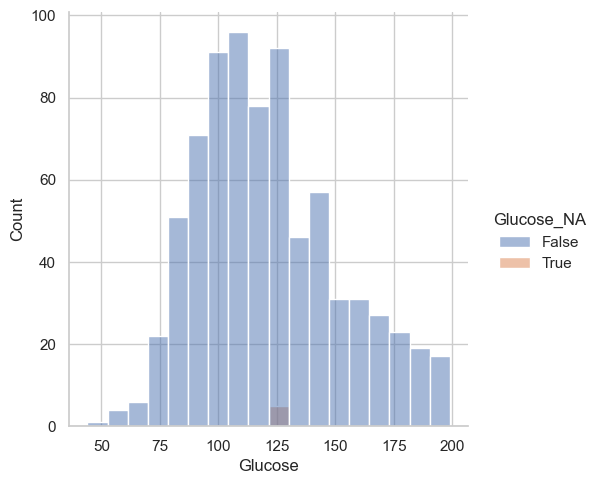

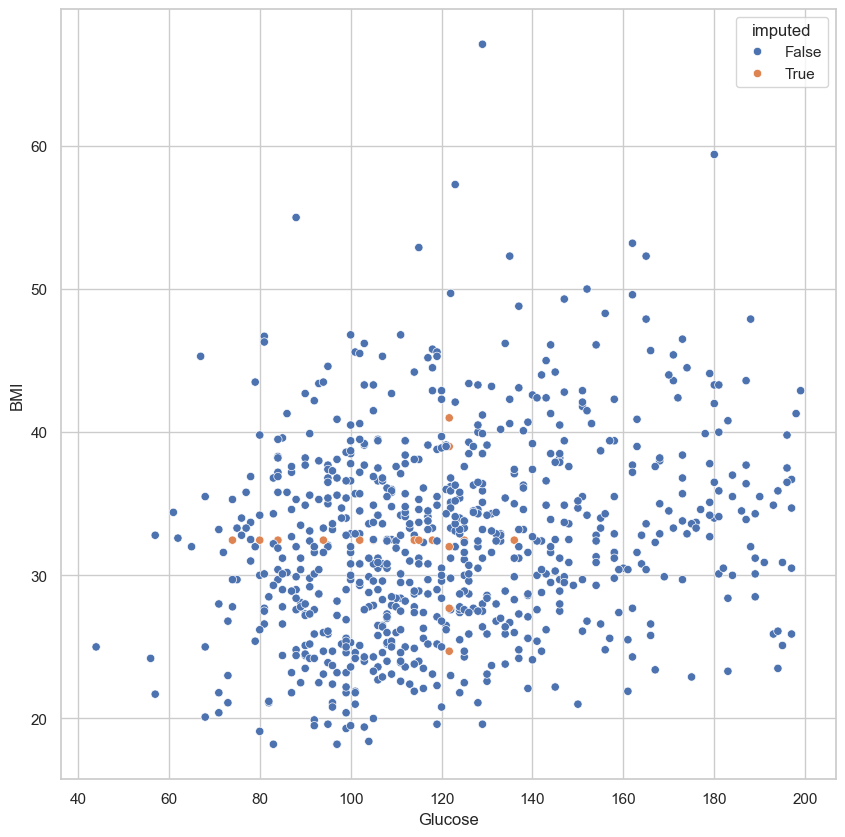

In [30]:
#IMPUTACION DE VALORES FALTANTES

implicit_to_explicit_df = pd.DataFrame(
    data={
        "name": ["lynn", np.nan, "zelda", np.nan, "shadowsong", np.nan],
        "time": ["morning", "afternoon", "morning", "afternoon", "morning", "afternoon",],
        "value": [350, 310, 320, 350, 310, 320]
    }
)

implicit_to_explicit_df.ffill() #En este caso, llena el valor faltante con el datos de arriba

#Ubicar los valores imputados a traves de un histograma
(
    diabetes
    .select_columns("Glucose", "Serum_Insulin", "BMI")
    .missing.bind_shadow_matrix(true_string=True, false_string=False)
    .apply(
        axis="rows",
        func=lambda column: column.fillna(column.mean()) if "_NA" not in column.name else column
    )
    .pipe(
        lambda df: (
            sns.displot(
                data=df,
                x="Glucose",
                hue="Glucose_NA"
            )
        )
    )
)


#Ubicar los valores imputados a traves de un scatterplot

plt.figure()
(
    diabetes
    .select_columns("Glucose", "Serum_Insulin", "BMI")
    .missing.bind_shadow_matrix(true_string=True, false_string=False)
    .apply(
        axis="rows",
        func=lambda column: column.fillna(column.mean()) if "_NA" not in column.name else column
    )
    .assign(
        imputed=lambda df: df.Glucose_NA | df.BMI_NA
    )
    .pipe(
        lambda df: (
            sns.scatterplot(
                data=df,
                x="Glucose",
                y="BMI",
                hue="imputed"
            )
        )
    )
)

c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas_flavor\register.py:157: FutureWarning: This function will be deprecated in a 1.x release. Please use `jn.select` instead.
  return method(self._obj, *args, **kwargs)


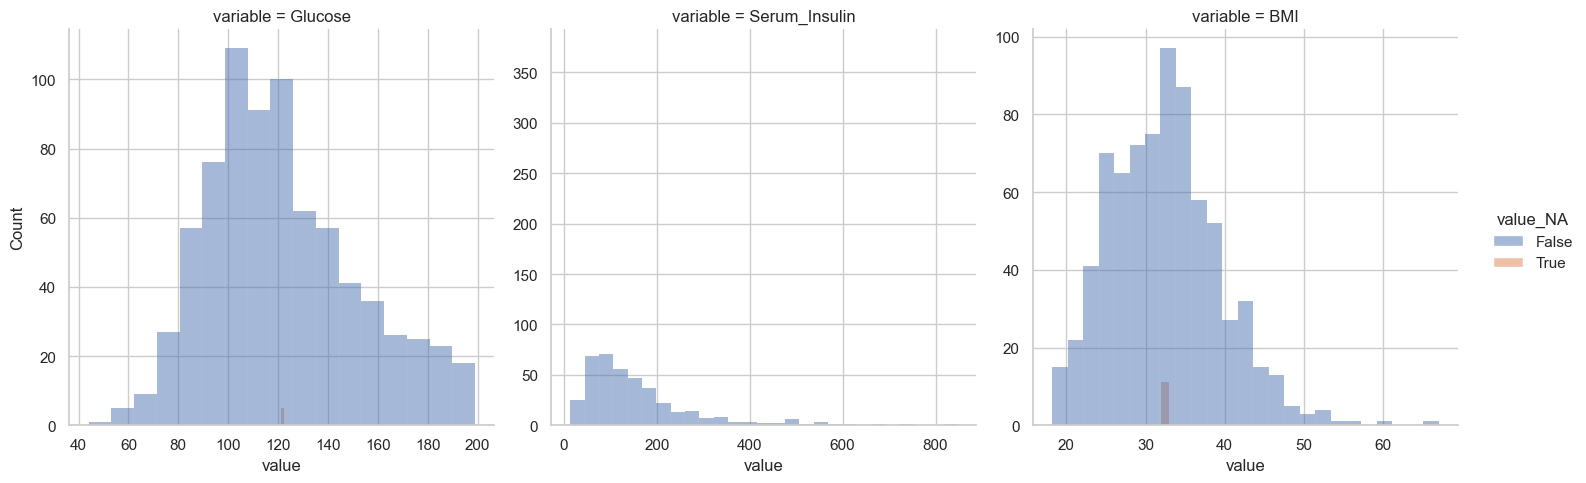

In [31]:
#Visualizacion multiple de imputaciones

# Seleccionar las columnas "Glucose", "Serum_Insulin" y "BMI" del dataframe diabetes.
(
    diabetes
    .select_columns("Glucose", "Serum_Insulin", "BMI")
    # Encadenar el método missing.bind_shadow_matrix para mostrar la matriz de sombra.
    # Configurar true_string y false_string para True y False respectivamente.
    .missing.bind_shadow_matrix(true_string=True, false_string=False)
    # Aplicar una función a lo largo de las filas del dataframe.
    # Rellenar los valores faltantes con la media de cada columna si el nombre de la columna no contiene "_NA".
    # De lo contrario, mantener los valores originales.
    .apply(
        axis="rows",
        func=lambda column: column.fillna(column.mean())
        if "_NA" not in column.name
        else column,
    )
    # Convertir el dataframe de formato ancho a formato largo utilizando la función pivot_longer.
    .pivot_longer(
        index="*_NA"
    )
    # Convertir el dataframe de formato ancho a formato largo nuevamente con más opciones de configuración.
    .pivot_longer(
        index=["variable", 'value'],
        names_to="variable_NA",
        values_to="value_NA"
    )
    # Asignar una nueva columna "valid" que indica si la variable original está presente en la variable "_NA".
    .assign(
        valid=lambda df: df.apply(axis="columns", func=lambda column: column.variable in column.variable_NA)
    )
    # Filtrar las filas donde la columna "valid" es verdadera.
    .query("valid")
    # Utilizar el método pipe para encadenar operaciones.
    .pipe(
        lambda df: (
            # Crear un histograma utilizando Seaborn con datos del dataframe df.
            sns.displot(
                data=df,
                x="value",
                hue="value_NA",
                col="variable",
                common_bins=False,
                facet_kws={
                    "sharex": False,
                    "sharey": False
                }
            )
        )
    )
)

